# QuickCart Warehouse Inventory — Stockout Risk Classification
**Task:** predict `Safe / At-Risk / Imminent` for every (store, SKU, day).  
**Primary metric:** Recall on **Imminent** (a missed stockout costs far more than a false alarm), tracked together with macro-F1.  
**Split:** time-based — train Oct 1–23, test Oct 24–30 (back half of Diwali week).

**Contents**
1. Load & locked sanity checks
2. Data-quality fixes (city casing, `'N/A'` reliability)
3. Joins → one modeling table
4. EDA: the three "money-moment" signals
5. Feature engineering
6. Models: baseline → Logistic Regression → Random Forest → Gradient Boosting
7. Leakage-aware ablation (with vs. without cover features)
8. Tuning the Imminent threshold for recall
9. Feature importance
10. Robustness: group split (unseen store-SKU pairs)
11. Business takeaways

In [1]:
import pandas as pd, numpy as np, warnings, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, recall_score,
                             precision_score, accuracy_score, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); RS=42
P='/mnt/user-data/uploads/'; FIG='/mnt/user-data/outputs/figures/'; os.makedirs(FIG,exist_ok=True)
LABELS=['Safe','At-Risk','Imminent']; MAP={l:i for i,l in enumerate(LABELS)}

## 1. Load & locked sanity checks
Explicit `na_values` instead of relying on pandas defaults (see §2).

In [2]:
NA=['N/A','missing','--','NA','null']
fact=pd.read_csv(P+'fact_inventory_daily.csv',parse_dates=['date'],na_values=NA,keep_default_na=True)
sup =pd.read_csv(P+'dim_suppliers.csv',na_values=NA,keep_default_na=True)
sto =pd.read_csv(P+'dim_stores.csv'); sku=pd.read_csv(P+'dim_skus.csv'); ev=pd.read_csv(P+'dim_events.csv',parse_dates=['date'])

vc=fact.stockout_risk.value_counts()
checks={'stores 12':len(sto)==12,'skus 60':len(sku)==60,'suppliers 15':len(sup)==15,'events 30':len(ev)==30,
 'fact 21,600':len(fact)==21600,'Safe 14,131':vc['Safe']==14131,'At-Risk 5,186':vc['At-Risk']==5186,'Imminent 2,283':vc['Imminent']==2283,
 '30 dates':fact.date.nunique()==30,'missing lead_time_actual 19,899':fact.lead_time_days_actual.isna().sum()==19899}
for k,v in checks.items(): print('PASS' if v else 'FAIL',k)
assert all(checks.values())

PASS stores 12
PASS skus 60
PASS suppliers 15
PASS events 30
PASS fact 21,600
PASS Safe 14,131
PASS At-Risk 5,186
PASS Imminent 2,283
PASS 30 dates
PASS missing lead_time_actual 19,899


## 2. Data-quality fixes
**(a) City casing** — `city_display` has 2 inconsistent rows. **(b) `'N/A'` reliability** — 3 suppliers. Missing values are imputed with the **median reliability of suppliers in the same primary category** (global median as fallback), per the spec guidance.

In [3]:
print(sto.loc[sto.city!=sto.city_display,['store_id','city','city_display']])
sto['city_display']=sto.city_display.str.title()
assert (sto.city==sto.city_display).all()

print('\nSuppliers with N/A reliability:', sup.loc[sup.reliability_score.isna(),'supplier_id'].tolist())
sup['primary_cat']=sup.categories_supplied.str.split(',').str[0].str.strip()
cat_med=sup.groupby('primary_cat').reliability_score.transform('median')
sup['reliability_missing']=sup.reliability_score.isna().astype(int)
sup['reliability_clean']=sup.reliability_score.fillna(cat_med).fillna(sup.reliability_score.median())
sup.loc[sup.reliability_missing==1,['supplier_id','primary_cat','reliability_score','reliability_clean']]

  store_id       city city_display
2     ST03  Bengaluru    BENGALURU
8     ST09  Hyderabad    hyderabad

Suppliers with N/A reliability: ['SUP06', 'SUP14', 'SUP15']


,supplier_id,primary_cat,reliability_score,reliability_clean
5,SUP06,Personal Care,NaN,0.720
13,SUP14,Staples,NaN,0.910
14,SUP15,Beverages,NaN,0.665


## 3. Joins → one modeling table
Grain stays 21,600 rows; every join is validated as many-to-one.

In [4]:
df=(fact.merge(sup[['supplier_id','reliability_clean','reliability_missing','lead_time_variance_days']],on='supplier_id',how='left',validate='m:1')
        .merge(sku.drop(columns='supplier_id'),on='sku_id',how='left',validate='m:1')
        .merge(sto,on='store_id',how='left',validate='m:1')
        .merge(ev,on='date',how='left',validate='m:1'))
assert len(df)==21600 and df.isna().sum().drop('lead_time_days_actual').sum()==0
df=df.sort_values(['store_id','sku_id','date']).reset_index(drop=True)
df.shape

(21600, 37)

## 4. EDA — verifying the three money-moment signals
The spec's reliability bucket cut (`pd.cut`) drops the 3 suppliers whose score is `N/A`. We show both: raw (NaN excluded) and imputed.

In [5]:
imm=(df.stockout_risk=='Imminent')
fest=imm.groupby(df.is_festival_week).mean()*100
print(f"Festival: non-festival {fest['N']:.2f}% | festival {fest['Y']:.2f}% | spike {fest['Y']/fest['N']:.2f}x")
per=imm.groupby(df.is_perishable).mean()*100
print(f"Perishable: non {per['N']:.1f}% | perishable {per['Y']:.1f}%")
raw=df.merge(sup[['supplier_id','reliability_score']],on='supplier_id')
b=[0,.75,.85,1.01]; lab=['<0.75','0.75-0.85','>=0.85']
r_raw=(raw.stockout_risk=='Imminent').groupby(pd.cut(raw.reliability_score,b,right=False,labels=lab)).mean()*100
r_imp=imm.groupby(pd.cut(df.reliability_clean,b,right=False,labels=lab)).mean()*100
print('\nImminent % by reliability bucket'); print(pd.DataFrame({'raw (N/A excluded)':r_raw,'imputed':r_imp}).round(2))

Festival: non-festival 9.51% | festival 23.31% | spike 2.45x
Perishable: non 9.3% | perishable 12.8%

Imminent % by reliability bucket
           raw (N/A excluded)  imputed
<0.75                   15.83    13.51
0.75-0.85                3.26     3.26
>=0.85                   3.82     5.03


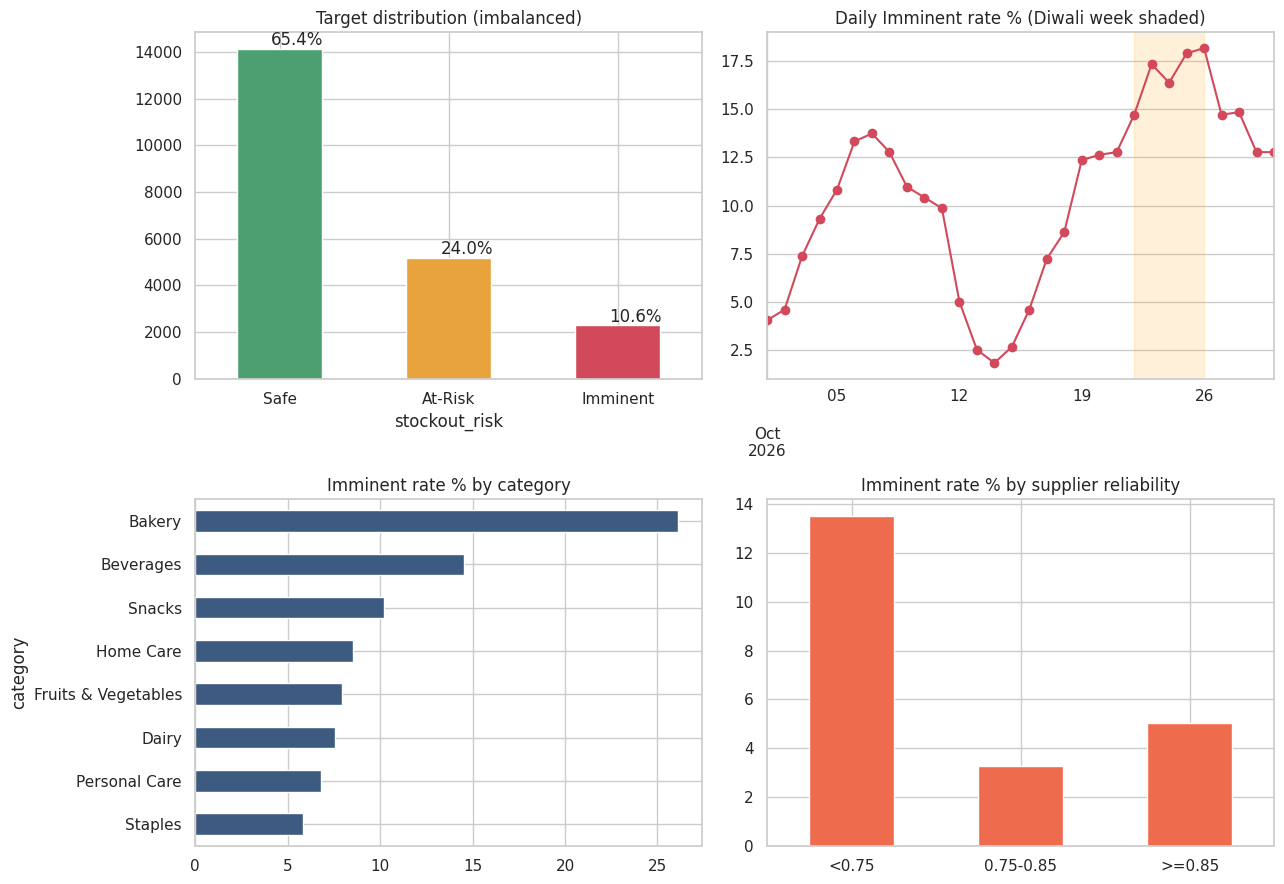

In [6]:
fig,ax=plt.subplots(2,2,figsize=(13,9))
vc.reindex(LABELS).plot.bar(ax=ax[0,0],color=['#4c9f70','#e8a33d','#d1495b'],rot=0); ax[0,0].set_title('Target distribution (imbalanced)')
for p in ax[0,0].patches: ax[0,0].annotate(f'{p.get_height()/len(df):.1%}',(p.get_x()+.2,p.get_height()+150))
daily=imm.groupby(df.date).mean()*100; daily.plot(ax=ax[0,1],marker='o',color='#d1495b'); ax[0,1].axvspan(pd.Timestamp('2026-10-22'),pd.Timestamp('2026-10-26'),alpha=.15,color='orange'); ax[0,1].set_title('Daily Imminent rate % (Diwali week shaded)'); ax[0,1].set_xlabel('')
(imm.groupby(df.category).mean()*100).sort_values().plot.barh(ax=ax[1,0],color='#3d5a80'); ax[1,0].set_title('Imminent rate % by category')
r_imp.plot.bar(ax=ax[1,1],rot=0,color='#ee6c4d'); ax[1,1].set_title('Imminent rate % by supplier reliability'); ax[1,1].set_xlabel('')
plt.tight_layout(); plt.savefig(FIG+'01_eda.png',dpi=130); plt.show()

## 5. Feature engineering
Spec-suggested features plus a few extras. Panel features use `groupby(store, sku)` + `shift` so they only look **backwards** (no leakage).

| Feature | Idea |
|---|---|
| `reorder_gap` | `reorder_point − closing_stock` |
| `days_of_cover_ratio`, `cover_minus_lt` | cover normalised by / net of expected lead time |
| `reliability_clean` (+ missing flag) | supplier reliability, N/A imputed |
| `reorders_last3`, `recent_reorder` | was an order placed in the previous 3 days |
| `unmet_last3` | days with unmet demand in the previous 3 days |
| `vel_chg`, `stk_chg` | momentum in velocity / stock |
| `eff_mult` | demand multiplier that actually applies to this SKU that day |
| `day_of_month`, `dow`, `days_since_festival_start` | temporal |
| category one-hot, ordinal popularity/size | |

In [7]:
g=df.groupby(['store_id','sku_id'])
df['reorder_gap']=df.reorder_point-df.closing_stock
df['days_of_cover_ratio']=df.days_of_cover/df.lead_time_days_expected
df['cover_minus_lt']=df.days_of_cover-df.lead_time_days_expected
df['_ro']=(df.reorder_placed=='Y').astype(int)
df['reorders_last3']=g['_ro'].transform(lambda x:x.shift(1).rolling(3,min_periods=1).sum()).fillna(0)
df['recent_reorder']=(df.reorders_last3>0).astype(int)
df['_unmet']=(df.units_demanded>df.units_sold).astype(int)
df['unmet_last3']=g['_unmet'].transform(lambda x:x.shift(1).rolling(3,min_periods=1).sum()).fillna(0)
df['vel_chg']=(df.sales_velocity_7d/g.sales_velocity_7d.shift(3)-1).replace([np.inf,-np.inf],np.nan).fillna(0).clip(-1,5)
df['stk_chg']=g.closing_stock.diff().fillna(0)
df['day_of_month']=df.date.dt.day; df['dow']=df.date.dt.dayofweek
df['days_since_festival_start']=(df.date-pd.Timestamp('2026-10-22')).dt.days
df['is_festival']=(df.is_festival_week=='Y').astype(int)
df['perishable']=(df.is_perishable=='Y').astype(int); df['festive_relevant_f']=(df.festive_relevant=='Y').astype(int)
df['eff_mult']=np.where(df.festive_relevant_f==1,df.demand_multiplier_festive,df.demand_multiplier_other)
df['popularity']=df.popularity_tier.map({'Low':0,'Medium':1,'High':2}); df['store_size_n']=df.store_size.map({'Small':0,'Medium':1,'Large':2})
cats=pd.get_dummies(df.category,prefix='cat').astype(int); df=pd.concat([df,cats],axis=1)

COVER=['days_of_cover','days_of_cover_ratio','cover_minus_lt']
BASE=['opening_stock','closing_stock','reorder_point','lead_time_days_expected','sales_velocity_7d','reorder_gap',
      'is_festival','perishable','festive_relevant_f','eff_mult','popularity','store_size_n','reliability_clean','reliability_missing',
      'lead_time_variance_days','unit_price_inr','shelf_life_days','baseline_daily_orders','recent_reorder','reorders_last3',
      'unmet_last3','vel_chg','stk_chg','day_of_month','dow','days_since_festival_start']+list(cats.columns)
FULL=BASE+COVER
y=df.stockout_risk.map(MAP)
print(len(FULL),'features; any NaN/inf:',df[FULL].isna().any().any() or np.isinf(df[FULL]).any().any())

37 features; any NaN/inf: False


## 6. Train / test split & models
Row-level random splits leak in a daily panel, so the split is **time-based**: train Oct 1–23 (16,560 rows) / test Oct 24–30 (5,040 rows).  
Note the test window is harder *and* different: Imminent share rises from ~10.6% overall to ~15% because it contains Diwali days.

In [8]:
tr=df.date<='2026-10-23'; te=~tr
Xtr,Xte,ytr,yte=df.loc[tr,FULL],df.loc[te,FULL],y[tr],y[te]
print('train',Xtr.shape,'test',Xte.shape); print('test class mix:',(yte.value_counts(normalize=True).sort_index().round(3)).to_dict())

def evaluate(name,model,X_tr,X_te):
    model.fit(X_tr,ytr); p=model.predict(X_te)
    r=recall_score(yte,p,average=None,labels=[0,1,2]); pr=precision_score(yte,p,average=None,labels=[0,1,2],zero_division=0)
    return dict(model=name,accuracy=accuracy_score(yte,p),macro_f1=f1_score(yte,p,average='macro'),
                recall_imminent=r[2],precision_imminent=pr[2],recall_atrisk=r[1],recall_safe=r[0]),model,p

models={
 'Majority baseline':DummyClassifier(strategy='most_frequent'),
 'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,class_weight='balanced',C=1.0)),
 'Random Forest':RandomForestClassifier(n_estimators=300,min_samples_leaf=3,class_weight='balanced',n_jobs=-1,random_state=RS),
 'Gradient Boosting (HGB)':HistGradientBoostingClassifier(class_weight='balanced',learning_rate=0.08,max_iter=300,random_state=RS)}
res,fitted,preds=[],{},{}
for n,m in models.items():
    r,fm,p=evaluate(n,m,Xtr,Xte); res.append(r); fitted[n]=fm; preds[n]=p
results=pd.DataFrame(res).set_index('model'); results.round(3)

train (16560, 37) test (5040, 37)
test class mix: {0: 0.623, 1: 0.223, 2: 0.154}


,accuracy,macro_f1,recall_imminent,precision_imminent,recall_atrisk,recall_safe
model,,,,,,
Majority baseline,0.623,0.256,0.000,0.000,0.000,1.000
Logistic Regression,0.906,0.842,0.923,0.673,0.655,0.992
Random Forest,0.948,0.904,0.777,0.878,0.925,0.998
Gradient Boosting (HGB),0.955,0.918,0.845,0.866,0.908,0.998


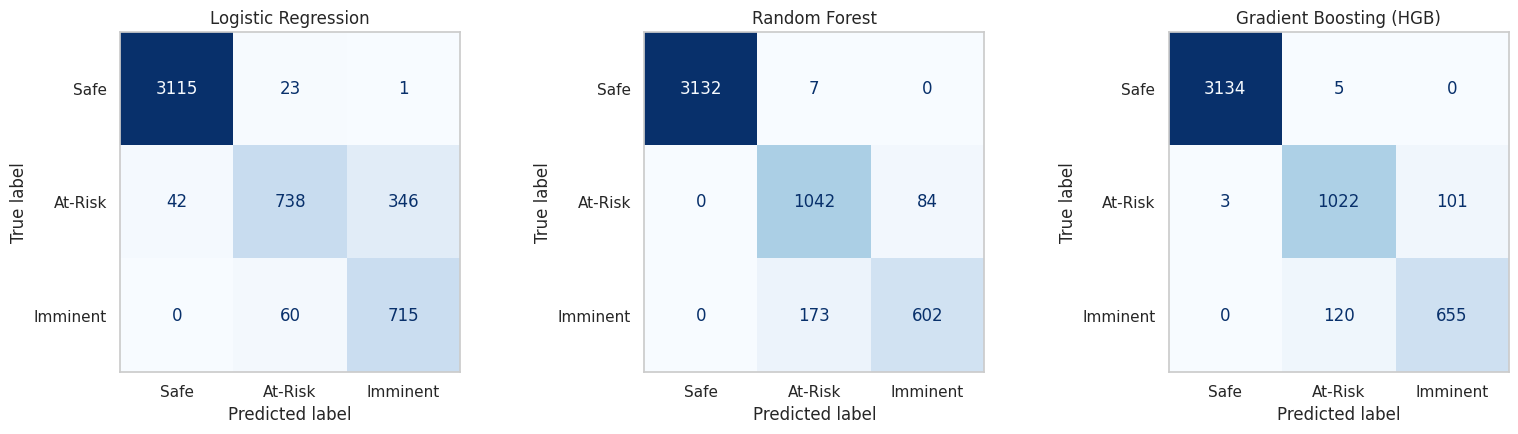

              precision    recall  f1-score   support

        Safe      0.999     0.998     0.999      3139
     At-Risk      0.891     0.908     0.899      1126
    Imminent      0.866     0.845     0.856       775

    accuracy                          0.955      5040
   macro avg      0.919     0.917     0.918      5040
weighted avg      0.955     0.955     0.955      5040



In [9]:
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for a,n in zip(ax,['Logistic Regression','Random Forest','Gradient Boosting (HGB)']):
    ConfusionMatrixDisplay(confusion_matrix(yte,preds[n],labels=[0,1,2]),display_labels=LABELS).plot(ax=a,cmap='Blues',colorbar=False,values_format='d'); a.set_title(n); a.grid(False)
plt.tight_layout(); plt.savefig(FIG+'02_confusion.png',dpi=130); plt.show()
print(classification_report(yte,preds['Gradient Boosting (HGB)'],target_names=LABELS,digits=3))

## 7. Leakage-aware ablation
The target is defined from *days of cover vs. replenishment wait*, so `days_of_cover` and its ratios are very close to the label definition. That is legitimate here (they're known at end-of-day and the question is operational), but it means a high score mostly reflects that definition. Dropping the three cover features shows how much the model can learn from the *underlying drivers* alone (stock, velocity, reorder point, supplier, festival…).

In [10]:
abl=[]
for n in ['Logistic Regression','Random Forest','Gradient Boosting (HGB)']:
    for tag,cols in [('with cover features',FULL),('without cover features',BASE)]:
        from sklearn.base import clone
        r,_,_=evaluate(n,clone(models[n]),df.loc[tr,cols],df.loc[te,cols]); r['features']=tag; abl.append(r)
ablation=pd.DataFrame(abl).set_index(['model','features']); ablation[['macro_f1','recall_imminent','precision_imminent','recall_atrisk']].round(3)

macro_f1  recall_imminent  \
model                   features                                            
Logistic Regression     with cover features        0.842            0.923   
                        without cover features     0.782            0.877   
Random Forest           with cover features        0.904            0.777   
                        without cover features     0.785            0.683   
Gradient Boosting (HGB) with cover features        0.918            0.845   
                        without cover features     0.824            0.724   

                                                precision_imminent  \
model                   features                                     
Logistic Regression     with cover features                  0.673   
                        without cover features               0.654   
Random Forest           with cover features                  0.878   
                        without cover features               0.880   
Gradient Boosting (HGB) with cover features                  0.866   
                        without cover features               0.851   

                                                recall_atrisk  
model                   features                               
Logistic Regression     with cover features             0.655  
                        without cover features          0.513  
Random Forest           with cover features             0.925  
                        without cover features          0.590  
Gradient Boosting (HGB) with cover features             0.908  
                        without cover features          0.691

## 8. Tuning the Imminent decision for recall
In the cost-asymmetric setting we scale the Imminent probability by a factor `w` before the argmax. `w` is chosen on a **validation slice inside the training period** (fit Oct 1–20, validate Oct 21–23) — the test set is never used for tuning. Target: Imminent recall ≥ 0.90 while keeping precision as high as possible.

In [11]:
def predict_w(proba,w): q=proba.copy(); q[:,2]*=w; return q.argmax(1)
sub=df.date<='2026-10-20'; val=(df.date>'2026-10-20')&(df.date<='2026-10-23')
m_val=HistGradientBoostingClassifier(class_weight='balanced',learning_rate=0.08,max_iter=300,random_state=RS).fit(df.loc[sub,FULL],y[sub])
pv=m_val.predict_proba(df.loc[val,FULL]); yv=y[val]
rows=[]
for w in [0.5,0.75,1,1.25,1.5,2,2.5,3,4,6]:
    p=predict_w(pv,w); rows.append((w,recall_score(yv,p,labels=[2],average=None)[0],precision_score(yv,p,labels=[2],average=None,zero_division=0)[0],f1_score(yv,p,average='macro')))
sweep=pd.DataFrame(rows,columns=['w','val_recall_imminent','val_precision_imminent','val_macro_f1']).set_index('w'); print(sweep.round(3))
ok=sweep[sweep.val_recall_imminent>=0.90]
W=ok.val_precision_imminent.idxmax() if len(ok) else sweep.val_recall_imminent.idxmax(); print('\nChosen w =',W)

final=fitted['Gradient Boosting (HGB)']; pt=final.predict_proba(Xte)
p_def=pt.argmax(1); p_tun=predict_w(pt,W)
cmp_=pd.DataFrame({'default (w=1)':[recall_score(yte,p_def,labels=[2],average=None)[0],precision_score(yte,p_def,labels=[2],average=None)[0],f1_score(yte,p_def,average='macro')],
                   f'tuned (w={W})':[recall_score(yte,p_tun,labels=[2],average=None)[0],precision_score(yte,p_tun,labels=[2],average=None)[0],f1_score(yte,p_tun,average='macro')]},
                  index=['recall_imminent','precision_imminent','macro_f1']).T
print('\nTEST SET'); print(cmp_.round(3))
print(pd.DataFrame(confusion_matrix(yte,p_tun,labels=[0,1,2]),index=['true '+l for l in LABELS],columns=['pred '+l for l in LABELS]))

      val_recall_imminent  val_precision_imminent  val_macro_f1
w                                                              
0.50                0.666                   0.799         0.857
0.75                0.709                   0.758         0.856
1.00                0.755                   0.731         0.858
1.25                0.780                   0.718         0.858
1.50                0.802                   0.706         0.858
2.00                0.833                   0.678         0.853
2.50                0.851                   0.656         0.847
3.00                0.864                   0.636         0.838
4.00                0.889                   0.605         0.826
6.00                0.926                   0.592         0.823

Chosen w = 6.0

TEST SET
               recall_imminent  precision_imminent  macro_f1
default (w=1)            0.845               0.866     0.918
tuned (w=6.0)            0.963               0.771     0.910
               pred Saf

## 9. Feature importance (permutation, on the test window)

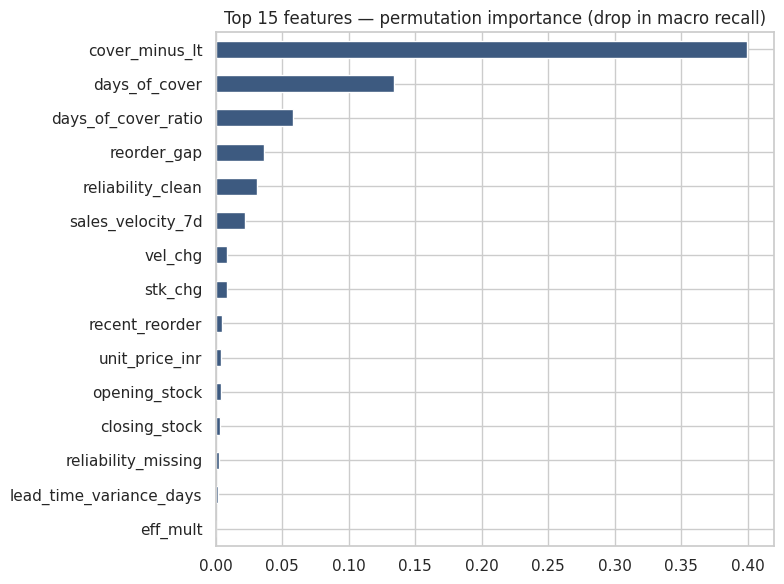

cover_minus_lt         0.3999
days_of_cover          0.1338
days_of_cover_ratio    0.0583
reorder_gap            0.0361
reliability_clean      0.0309
sales_velocity_7d      0.0217
vel_chg                0.0087
stk_chg                0.0087
recent_reorder         0.0050
unit_price_inr         0.0041
dtype: float64

In [12]:
pi=permutation_importance(final,Xte,yte,scoring='recall_macro',n_repeats=5,random_state=RS,n_jobs=-1)
imp=pd.Series(pi.importances_mean,index=FULL).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8,6)); imp.head(15)[::-1].plot.barh(ax=ax,color='#3d5a80'); ax.set_title('Top 15 features — permutation importance (drop in macro recall)'); plt.tight_layout(); plt.savefig(FIG+'03_importance.png',dpi=130); plt.show()
imp.head(10).round(4)

In [13]:
# No-cover model: what do the *drivers* look like? (where do festival & supplier signals show up)
nc=HistGradientBoostingClassifier(class_weight='balanced',learning_rate=0.08,max_iter=300,random_state=RS).fit(df.loc[tr,BASE],ytr)
pi2=permutation_importance(nc,df.loc[te,BASE],yte,scoring='recall_macro',n_repeats=5,random_state=RS,n_jobs=-1)
imp2=pd.Series(pi2.importances_mean,index=BASE).sort_values(ascending=False); imp2.head(10).round(4)

reorder_gap                0.4009
sales_velocity_7d          0.1404
closing_stock              0.0929
lead_time_days_expected    0.0252
reorder_point              0.0246
reliability_clean          0.0201
opening_stock              0.0140
vel_chg                    0.0106
stk_chg                    0.0104
eff_mult                   0.0037
dtype: float64

## 10. Robustness — group split (unseen store-SKU pairs)
5-fold `GroupKFold` over store-SKU pairs (720 groups): the model is scored on pairs it has never seen on *any* day.

In [14]:
grp=df.store_id+'_'+df.sku_id; rows=[]
for k,(a,b) in enumerate(GroupKFold(5).split(df,y,grp)):
    m=HistGradientBoostingClassifier(class_weight='balanced',learning_rate=0.08,max_iter=300,random_state=RS).fit(df.loc[a,FULL],y[a]); p=m.predict(df.loc[b,FULL])
    rows.append((k,f1_score(y[b],p,average='macro'),recall_score(y[b],p,labels=[2],average=None)[0],precision_score(y[b],p,labels=[2],average=None)[0]))
gk=pd.DataFrame(rows,columns=['fold','macro_f1','recall_imminent','precision_imminent']).set_index('fold'); print(gk.round(3)); print('\nmean:'); print(gk.mean().round(3))

      macro_f1  recall_imminent  precision_imminent
fold                                               
0        0.874            0.765               0.724
1        0.851            0.644               0.735
2        0.864            0.663               0.826
3        0.871            0.760               0.720
4        0.879            0.765               0.743

mean:
macro_f1              0.868
recall_imminent       0.719
precision_imminent    0.749
dtype: float64


## 11. Business takeaways
*(Numbers below refer to the outputs above; see the README for the final summary table.)*
1. **Festival week is the biggest operational lever** — Imminent rate rises ~2.45× during Diwali week. Pre-load festive-relevant SKUs (Snacks, Beverages, Bakery) *before* Oct 22.
2. **Supplier reliability is the second lever** — suppliers scoring < 0.75 run a far higher Imminent rate than reliable ones. Escalate / dual-source these.
3. **Perishables** carry a modestly higher risk (tighter cover targets).
4. **Model usage:** run the tuned Gradient Boosting model daily; treat *Imminent* predictions as an expedite list and *At-Risk* as the next-day watch list. Because the target is defined from cover vs. lead time, a high score is expected — the ablation in §7 shows the model still learns real signal without the cover features, but with a clear drop (mainly on At-Risk).
5. **Caveats:** only 30 days of data (one festival); a single Diwali week means festival effects can't be validated across years; thresholds should be re-tuned once real replenishment costs are known.